## Assignment: $k$ Means Clustering


**Q1.** This is a question about clustering. We want to investigate how adjusting the "noisiness" of the data impacts the quality of the algorithm and the difficulty of picking $k$.

1. Run the code below, which creates four datasets: `df0_125`, `df0_25`, `df0_5`, `df1_0`, and `df2_0`. Each data set is created by increasing the amount of `noise` (standard deviation) around the cluster centers, from `0.125` to `0.25` to `0.5` to `1.0` to `2.0`.

```
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)
```

2. Make scatterplots of the $(X1,X2)$ points by group for each of the datasets. As the `noise` goes up from 0.125 to 2.0, what happens to the visual distinctness of the clusters?
3. Create a scree plot for each of the datasets. Describe how the level of `noise` affects the scree plot (particularly the presence of a clear "elbow") and your ability to definitively select a $k$. (Pay attention to the vertical axis across plots, or put all the scree curves on a single canvas.)
4. Explain the intuition of the elbow, using this numerical simulation as an example.

**Q2.** This question is a case study on clustering.

1. Load the `SIPRI Military Expenditure Database.csv` file in the `./data` folder. This has data about military spending by country. Filter the rows to select only the year 2020, and drop all rows with missing values. I ended up with 148 countries. Is any further cleaning of the variables required?
2. Max-min normalize `Spending (2020 USD)` and `Spending per Capita`. Use a scree plot to determine the optimal number of clusters for the $k$ means clustering algorithm. Make a scatter plot of `Spending (2020 USD)` and `Spending per Capita`, and hue the dots by their cluster membership. Compute a describe table conditional on cluster membership (i.e. `.groupby(cluster).describe()`). What do you see? Where is the United States? Do you notice any patterns in the cluster membership?
3. Repeat part 2 for `Percent of Government Spending` and `Percent of GDP`. How do your results compare to part 2?
4. Use $k$ means clustering with all four numeric variables: `Spending (2020 USD)`, `Spending per Capita`, `Percent of Government Spending`, and `Percent of GDP`. How do your results compare to the previous two parts? 
5. Did the $k$-MC algorithm find any useful patterns for you in analyzing the spending?

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** Claire McGinn

**Date:** 10/7/26

### Question 1

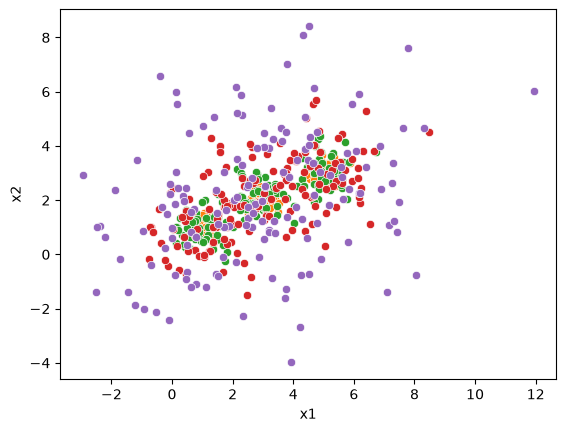

In [1]:
# Your Phase 1 solution to the problem goes here.

#1.1
import numpy as np
import pandas as pd

def createData(noise,N=50):
    np.random.seed(100) # Set the seed for replicability
    # Generate (x1,x2,g) triples:
    X1 = np.array([np.random.normal(1,noise,N),np.random.normal(1,noise,N)])
    X2 = np.array([np.random.normal(3,noise,N),np.random.normal(2,noise,N)])
    X3 = np.array([np.random.normal(5,noise,N),np.random.normal(3,noise,N)])
    # Concatenate into one data frame
    gdf1 = pd.DataFrame({'x1':X1[0,:],'x2':X1[1,:],'group':'a'})
    gdf2 = pd.DataFrame({'x1':X2[0,:],'x2':X2[1,:],'group':'b'})
    gdf3 = pd.DataFrame({'x1':X3[0,:],'x2':X3[1,:],'group':'c'})
    df = pd.concat([gdf1,gdf2,gdf3],axis=0)
    return df

df0_125 = createData(0.125)
df0_25 = createData(0.25)
df0_5 = createData(0.5)
df1_0 = createData(1.0)
df2_0 = createData(2.0)

#1.2

import seaborn as sns
ax_0_125 = sns.scatterplot(data = df0_125, x = 'x1', y = 'x2') #add hue
ax_0_25 = sns.scatterplot(data = df0_25, x = 'x1', y = 'x2')
ax_0_5 = sns.scatterplot(data = df0_5, x = 'x1', y = 'x2')
ax_1_0 = sns.scatterplot(data = df1_0, x = 'x1', y = 'x2')
ax_2_0 = sns.scatterplot(data = df2_0, x = 'x1', y = 'x2')
# As the noise is increased, the data beigns to become less clustered around certain points. There are more present outliers and the correlation between points decreases.



[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

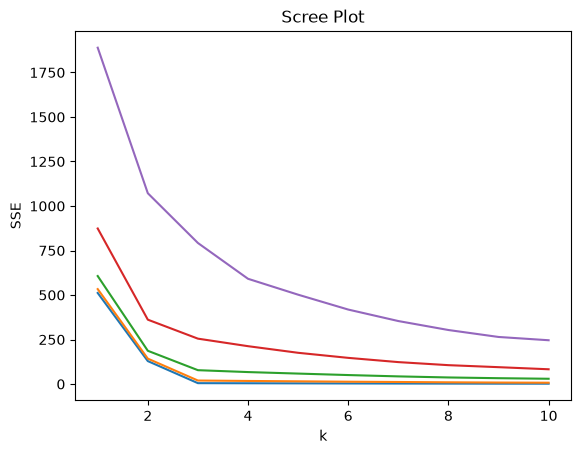

In [2]:
#1.3

from sklearn.cluster import KMeans

ks = np.arange(1, 11)
X1 = df0_125[['x1','x2']]
X2 = df0_25[['x1','x2']]
X3 = df0_5[['x1','x2']]
X4 = df1_0[['x1','x2']]
X5 = df2_0[['x1','x2']]

SSE = [KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0).fit(X1).inertia_
       for k in ks]
sns.lineplot(x = ks, y = SSE).set(title = "Scree Plot", xlabel = "k", ylabel = "SSE")
SSE = [KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0).fit(X2).inertia_
       for k in ks]
sns.lineplot(x = ks, y = SSE).set(title = "Scree Plot", xlabel = "k", ylabel = "SSE")
SSE = [KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0).fit(X3).inertia_
       for k in ks]
sns.lineplot(x = ks, y = SSE).set(title = "Scree Plot", xlabel = "k", ylabel = "SSE")
SSE = [KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0).fit(X4).inertia_
       for k in ks]
sns.lineplot(x = ks, y = SSE).set(title = "Scree Plot", xlabel = "k", ylabel = "SSE")
SSE = [KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0).fit(X5).inertia_
       for k in ks]
sns.lineplot(x = ks, y = SSE).set(title = "Scree Plot", xlabel = "k", ylabel = "SSE")

# As the noise increases, the K is still in the same spot on the y axis, it just increases its SSE value as the noise increses. This makes it more clear what the true k value is because even when the noise increases, the elbow is still at k = 2, which is the true k value.

# 1.4
# The elbow intuites that k = 2 because even as the noise increase, the elbow of the scree plot is still in the same place on each plot.

### Question 2 

#### 2.1

In [3]:
#2.1
df = pd.read_csv('./data/SIPRI Military Expenditure Database.csv')
df.loc[:, ['Year','Country','Spending (2020 USD)']].head()


,Year,Country,Spending (2020 USD)
0,1988,Afghanistan,NaN
1,1989,Afghanistan,NaN
2,1990,Afghanistan,NaN
3,1991,Afghanistan,NaN
4,1992,Afghanistan,NaN


In [4]:
filtered_df = df[df['Year'] == 2020]
filtered_df = filtered_df.dropna().copy() 
filtered_df["Country"].value_counts()


Country
Afghanistan                 1
Albania                     1
Algeria                     1
Angola                      1
Argentina                   1
                           ..
United Kingdom              1
United States of America    1
Uruguay                     1
Zambia                      1
Zimbabwe                    1
Name: count, Length: 148, dtype: int64

In [5]:
filtered_df.isna().sum()
# I got 148 countries. Additional cleaning could involve manually checking the data for errors, such as missing values or incorrect data types. Checking with isna().sum() helped to clearly see that the NaNs were dropped.

index                             0
Year                              0
Country                           0
Spending (2020 USD)               0
Percent of GDP                    0
Percent of Government Spending    0
Spending per Capita               0
dtype: int64

#### 2.2

In [6]:
from sklearn.cluster import KMeans

features = ["Spending (2020 USD)", "Spending per Capita"]
unscaled = filtered_df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])

,Spending (2020 USD),Spending per Capita
min,0.0,0.0
max,1.0,1.0


[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

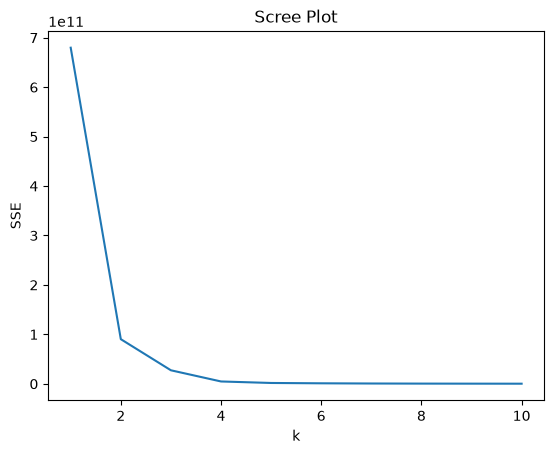

In [7]:
ks = np.arange(1, 11)
X = filtered_df[["Spending (2020 USD)", "Spending per Capita"]]
SSE = [KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0).fit(X).inertia_
       for k in ks]
sns.lineplot(x = ks, y = SSE).set(title = "Scree Plot", xlabel = "k", ylabel = "SSE")
# I chose k=3 because there is an elbow at k=3. Even though there is a an elbow at k=2, I wanted to have a higher k value to see if there were any other clusters that could be found. I also wanted to see if the elbow at k=2 was a true elbow or not, and by increasing the k value, I was able to see that it was a true elbow.

In [8]:
k = 3
model = KMeans(
    n_clusters=k, max_iter=1,
    n_init=1, random_state=0
).fit(X)
model

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",1
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[[ 6235.5

In [9]:
filtered_df['Cluster'] = model.labels_
filtered_df

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Cluster
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899,0
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211,0
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384,0
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680,0
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731,0
...,...,...,...,...,...,...,...,...
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388,0
5540,5540,2020,United States of America,778397.200000,0.037179,0.081976,2351.631858,1
5574,5574,2020,Uruguay,1091.535360,0.021777,0.062082,314.201312,0
5846,5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514,0


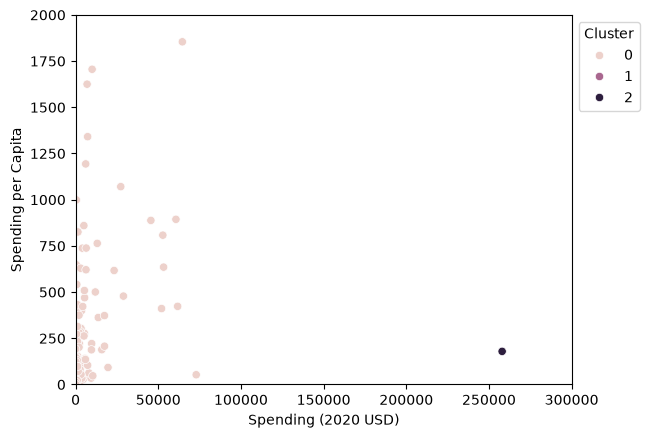

In [10]:
ax = sns.scatterplot(data=filtered_df, x="Spending (2020 USD)", y="Spending per Capita", hue="Cluster")
ax.set_xlim(0, 300000)
ax.set_ylim(0, 2000)
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [11]:
filtered_df.groupby('Cluster').describe()

# Based on the table, I can see that the cluster with the most countries in cluster 0. Only two countries were in the other clusters.

index                                                            \
         count         mean          std     min     25%     50%     75%   
Cluster                                                                    
0        146.0  2824.890411  1643.769579    32.0  1443.0  2871.0  4205.5   
1          1.0  5540.000000          NaN  5540.0  5540.0  5540.0  5540.0   
2          1.0  1052.000000          NaN  1052.0  1052.0  1052.0  1052.0   

                  Year          ... Percent of Government Spending            \
            max  count    mean  ...                            75%       max   
Cluster                         ...                                            
0        5880.0  146.0  2020.0  ...                       0.085780  0.303027   
1        5540.0    1.0  2020.0  ...                       0.081976  0.081976   
2        1052.0    1.0  2020.0  ...                       0.047517  0.047517   

        Spending per Capita                                        \
                      count         mean         std          min   
Cluster                                                             
0                     146.0   254.604663  397.055685     0.580129   
1                       1.0  2351.631858         NaN  2351.631858   
2                       1.0   179.232355         NaN   179.232355   

                                                             
                 25%          50%          75%          max  
Cluster                                                      
0          20.375457    80.521476   311.580228  2520.398541  
1        2351.631858  2351.631858  2351.631858  2351.631858  
2         179.232355   179.232355   179.232355   179.232355  

[3 rows x 48 columns]

In [12]:
clustered_summary = filtered_df.loc[filtered_df['Country'] == 'United States of America']
clustered_summary 

# For the Unites States, it is in cluster 1 and makes up a higher percent of spending per capita than other countries. It is the only country in cluster 1.It also has a higher spending in 2020 USD than other countries. 


,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Cluster
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,1


#### 2.3

In [13]:
features = ["Percent of Government Spending", "Percent of GDP"]
unscaled = filtered_df.loc[:, features]
mins = unscaled.min()
ranges = unscaled.max() - mins
X = (unscaled - mins) / ranges
X.agg(["min", "max"])


,Percent of Government Spending,Percent of GDP
min,0.0,0.0
max,1.0,1.0


[Text(0.5, 1.0, 'Scree Plot'), Text(0.5, 0, 'k'), Text(0, 0.5, 'SSE')]

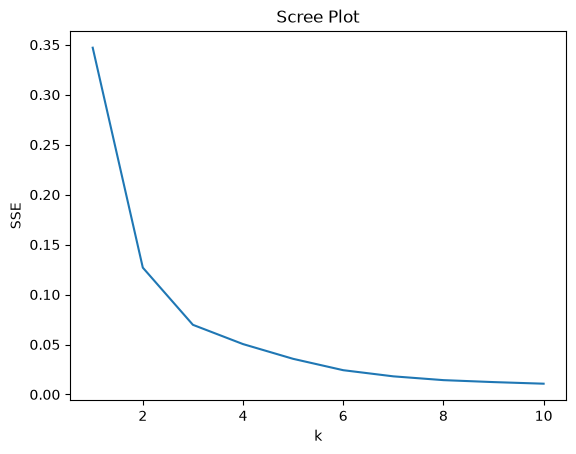

In [14]:
ks = np.arange(1, 11)
X = filtered_df[["Percent of Government Spending", "Percent of GDP"]]
SSE = [KMeans(n_clusters = k, max_iter = 300, n_init = 10, random_state = 0).fit(X).inertia_
       for k in ks]
sns.lineplot(x = ks, y = SSE).set(title = "Scree Plot", xlabel = "k", ylabel = "SSE")

In [15]:
k = 3
model = KMeans(
    n_clusters=k, max_iter=1,
    n_init=1, random_state=0
).fit(X)
model

,"n_clusters n_clusters: int, default=8The number of clusters to form as well as the number ofcentroids to generate.For an example of how to choose an optimal value for `n_clusters` refer to:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_silhouette_analysis.py`.",3
,"n_init n_init: 'auto' or int, default='auto'Number of times the k-means algorithm is run with different centroidseeds. The final results is the best output of `n_init` consecutive runsin terms of inertia. Several runs are recommended for sparsehigh-dimensional problems (see :ref:`kmeans_sparse_high_dim`).When `n_init='auto'`, the number of runs depends on the value of init:10 if using `init='random'` or `init` is a callable;1 if using `init='k-means++'` or `init` is an array-like... versionadded:: 1.2 Added 'auto' option for `n_init`... versionchanged:: 1.4 Default value for `n_init` changed to `'auto'`.",1
,"max_iter max_iter: int, default=300Maximum number of iterations of the k-means algorithm for asingle run.",1
,"random_state random_state: int, RandomState instance or None, default=NoneDetermines random number generation for centroid initialization. Usean int to make the randomness deterministic.See :term:`Glossary <random_state>`.",0
,"init init: {'k-means++', 'random'}, callable or array-like of shape (n_clusters, n_features), default='k-means++'Method for initialization:* 'k-means++' : selects initial cluster centroids using sampling based on an empirical probability distribution of the points' contribution to the overall inertia. This technique speeds up convergence. The algorithm implemented is ""greedy k-means++"". It differs from the vanilla k-means++ by making several trials at each sampling step and choosing the best centroid among them.* 'random': choose `n_clusters` observations (rows) at random from data for the initial centroids.* If an array is passed, it should be of shape (n_clusters, n_features) and gives the initial centers.* If a callable is passed, it should take arguments X, n_clusters and a random state and return an initialization.For an example of how to use the different `init` strategies, see:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_digits.py`.For an evaluation of the impact of initialization, see the example:ref:`sphx_glr_auto_examples_cluster_plot_kmeans_stability_low_dim_dense.py`.",'k-means++'
,"tol tol: float, default=1e-4Relative tolerance with regards to Frobenius norm of the differencein the cluster centers of two consecutive iterations to declareconvergence.",0.0001
,"verbose verbose: int, default=0Verbosity mode.",0
,"copy_x copy_x: bool, default=TrueWhen pre-computing distances it is more numerically accurate to centerthe data first. If copy_x is True (default), then the original data isnot modified. If False, the original data is modified, and put backbefore the function returns, but small numerical differences may beintroduced by subtracting and then adding the data mean. Note that ifthe original data is not C-contiguous, a copy will be made even ifcopy_x is False. If the original data is sparse, but not in CSR format,a copy will be made even if copy_x is False.",True
,"algorithm algorithm: {""lloyd"", ""elkan""}, default=""lloyd""K-means algorithm to use. The classical EM-style algorithm is `""lloyd""`.The `""elkan""` variation can be more efficient on some datasets withwell-defined clusters, by using the triangle inequality. However it'smore memory intensive due to the allocation of an extra array of shape`(n_samples, n_clusters)`... versionchanged:: 0.18 Added Elkan algorithm.. versionchanged:: 1.1 Renamed ""full"" to ""lloyd"", and deprecated ""auto"" and ""full"". Changed ""auto"" to use ""lloyd"" instead of ""elkan"".",'lloyd'
Name,Type,Value
"cluster_centers_ cluster_centers_: ndarray of shape (n_clusters, n_features)Coordinates of cluster centers. If the algorithm stops before fullyconverging (see ``tol`` and ``max_iter``), these will not beconsistent with ``labels_``.","ndarray[float64](3, 2)","[[0.06,0.

In [16]:
filtered_df['Cluster'] = model.labels_
filtered_df

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Cluster
32,32,2020,Afghanistan,279.576955,0.013589,0.049728,7.181899,0
66,66,2020,Albania,187.433234,0.012583,0.037952,65.126211,2
100,100,2020,Algeria,9708.277440,0.066600,0.173924,221.392384,1
134,134,2020,Angola,993.594405,0.014442,0.074624,30.231680,0
168,168,2020,Argentina,2830.929705,0.007269,0.017268,62.636731,2
...,...,...,...,...,...,...,...,...
5506,5506,2020,United Kingdom,60675.039625,0.022408,0.045629,893.778388,0
5540,5540,2020,United States of America,778397.200000,0.037179,0.081976,2351.631858,0
5574,5574,2020,Uruguay,1091.535360,0.021777,0.062082,314.201312,0
5846,5846,2020,Zambia,212.142427,0.011542,0.034261,11.539514,2


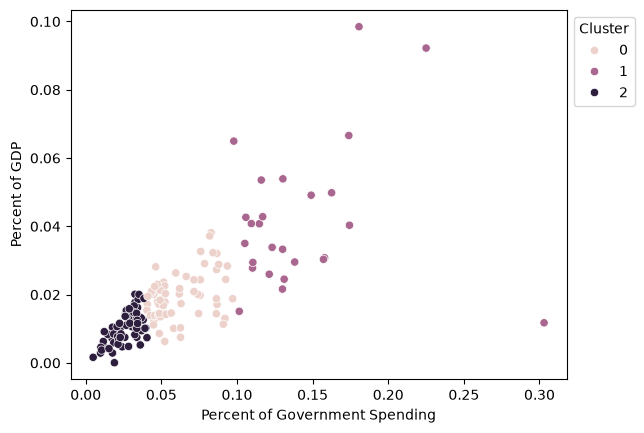

In [17]:
ax = sns.scatterplot(data=filtered_df, x="Percent of Government Spending", y="Percent of GDP", hue="Cluster")
sns.move_legend(ax, "upper left", bbox_to_anchor=(1, 1))

In [18]:
clustered_summary = filtered_df.groupby('Country').describe()
clustered_summary

# The data is in a much clearer pattern in this plot. There is a positive linear relationship between X and Y.

index                                              \
                         count    mean std     min     25%     50%     75%   
Country                                                                      
Afghanistan                1.0    32.0 NaN    32.0    32.0    32.0    32.0   
Albania                    1.0    66.0 NaN    66.0    66.0    66.0    66.0   
Algeria                    1.0   100.0 NaN   100.0   100.0   100.0   100.0   
Angola                     1.0   134.0 NaN   134.0   134.0   134.0   134.0   
Argentina                  1.0   168.0 NaN   168.0   168.0   168.0   168.0   
...                        ...     ...  ..     ...     ...     ...     ...   
United Kingdom             1.0  5506.0 NaN  5506.0  5506.0  5506.0  5506.0   
United States of America   1.0  5540.0 NaN  5540.0  5540.0  5540.0  5540.0   
Uruguay                    1.0  5574.0 NaN  5574.0  5574.0  5574.0  5574.0   
Zambia                     1.0  5846.0 NaN  5846.0  5846.0  5846.0  5846.0   
Zimbabwe                   1.0  5880.0 NaN  5880.0  5880.0  5880.0  5880.0   

                                  Year          ... Spending per Capita  \
                             max count    mean  ...                 75%   
Country                                         ...                       
Afghanistan                 32.0   1.0  2020.0  ...            7.181899   
Albania                     66.0   1.0  2020.0  ...           65.126211   
Algeria                    100.0   1.0  2020.0  ...          221.392384   
Angola                     134.0   1.0  2020.0  ...           30.231680   
Argentina                  168.0   1.0  2020.0  ...           62.636731   
...                          ...   ...     ...  ...                 ...   
United Kingdom            5506.0   1.0  2020.0  ...          893.778388   
United States of America  5540.0   1.0  2020.0  ...         2351.631858   
Uruguay                   5574.0   1.0  2020.0  ...          314.201312   
Zambia                    5846.0   1.0  2020.0  ...           11.539514   
Zimbabwe                  5880.0   1.0  2020.0  ...            0.580129   

                                      Cluster                               \
                                  max   count mean std  min  25%  50%  75%   
Country                                                                      
Afghanistan                  7.181899     1.0  0.0 NaN  0.0  0.0  0.0  0.0   
Albania                     65.126211     1.0  2.0 NaN  2.0  2.0  2.0  2.0   
Algeria                    221.392384     1.0  1.0 NaN  1.0  1.0  1.0  1.0   
Angola                      30.231680     1.0  0.0 NaN  0.0  0.0  0.0  0.0   
Argentina                   62.636731     1.0  2.0 NaN  2.0  2.0  2.0  2.0   
...                               ...     ...  ...  ..  ...  ...  ...  ...   
United Kingdom             893.778388     1.0  0.0 NaN  0.0  0.0  0.0  0.0   
United States of America  2351.631858     1.0  0.0 NaN  0.0  0.0  0.0  0.0   
Uruguay                    314.201312     1.0  0.0 NaN  0.0  0.0  0.0  0.0   
Zambia                      11.539514     1.0  2.0 NaN  2.0  2.0  2.0  2.0   
Zimbabwe                     0.580129     1.0  2.0 NaN  2.0  2.0  2.0  2.0   

                               
                          max  
Country                        
Afghanistan               0.0  
Albania                   2.0  
Algeria                   1.0  
Angola                    0.0  
Argentina                 2.0  
...                       ...  
United Kingdom            0.0  
United States of America  0.0  
Uruguay                   0.0  
Zambia                    2.0  
Zimbabwe                  2.0  

[148 rows x 56 columns]

In [19]:
clustered_summary = filtered_df.loc[filtered_df['Country'] == 'United States of America']
clustered_summary 

# The United States is in cluster 3. It is not as significant of an outlier in this data set.

,index,Year,Country,Spending (2020 USD),Percent of GDP,Percent of Government Spending,Spending per Capita,Cluster
5540,5540,2020,United States of America,778397.2,0.037179,0.081976,2351.631858,0


#### 2.4

<Axes: xlabel='Percent of Government Spending', ylabel='Percent of GDP'>

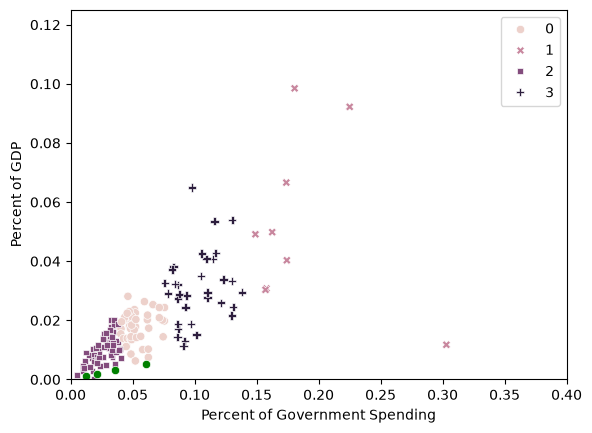

In [20]:
#2.4

model = KMeans(n_clusters=4, n_init="auto", random_state=0).fit(X)
filtered_df["Cluster"] = model.labels_
centers = model.cluster_centers_ * ranges.to_numpy() + mins.to_numpy()
ax = sns.scatterplot(
    data=filtered_df, x="Percent of Government Spending", y="Percent of GDP", hue="Cluster", style="Cluster"
)
ax.set_xlim(0, 0.4)
ax.set_ylim(0, 0.125)
sns.scatterplot(x=centers[:, 0], y=centers[:, 1], color="green", ax=ax)

#The results are fairly similar in that the data is clustered around the origin. It more closely resembles the data from 2.2.

In [21]:
#2.6
# A useful pattern that kMC helped me see in the data is that higher GDP countries tended to be farther from the origin.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [22]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]